In [119]:
import numpy as np
import matplotlib.pyplot as plt
from math import pi
import matplotlib
from tqdm import tqdm

# matplotlib.rcParams['font.family'] = 'STIX Two Text'
# matplotlib.rcParams['font.size'] = 10

In [120]:
def phaseField(X,Y,focalPoint,m):

    P0 = np.ones(X.shape, dtype=complex)

    out = addPointFocus(P0, X, Y, focalPoint)

    # out = addLinearFocus(P0, X, Y, focalPoint, angle=pi/4)

    out = addVortex(out, X, Y, m)

    # out = addBottle(out, X, Y, aperature/(2*np.sqrt(2))) # bottle trap with given radius

    # for n in range(1, m+1):
    #     angle = n * (pi / abs(m))
    #     print(f'Adding twin trap at angle: {angle*180/pi:.2f} degrees')
    #     out = addTwin(out, X, Y, angle)
        
    return out

def addPointFocus(P0,X, Y, focalPoint):
    Xf = X - focalPoint[0]
    Yf = Y - focalPoint[1]
    Zf = focalPoint[2]
    
    r = np.sqrt(Xf**2 + Yf**2 + Zf**2)

    P_Focus = np.copy(P0)
    P_Focus *= np.exp(1j*k*r)
    
    return P_Focus

def addLinearFocus(P0,X, Y, focalPoint,angle):
    Xf = X - focalPoint[0]
    Yf = Y - focalPoint[1]
    Zf = focalPoint[2]

    X_rot = X * np.cos(angle) + Y * np.sin(angle)

    
    r = np.sqrt(X_rot**2 + Zf**2)

    P_Focus = np.copy(P0)
    P_Focus *= np.exp(1j*k*r)
    
    return P_Focus

def addVortex(P0,X, Y, m):
    theta = np.arctan2(Y, X)

    P_Vortex = np.copy(P0)
    P_Vortex *= np.exp(1j * m * theta)
    
    return P_Vortex

def addTwin(P0,X, Y, angle):
    # rotate coordinates by the given angle and build mask
    X_rot = X * np.cos(angle) + Y * np.sin(angle)
    mask = X_rot > 0

    P_Twin = np.copy(P0)
    P_Twin[mask>0] *= np.exp(1j*pi)
    
    return P_Twin

def addBottle(P0,X, Y, radius):
    r = np.sqrt(X**2 + Y**2)
    mask = r < radius

    P_Bottle = np.copy(P0)
    P_Bottle[mask>0] *= np.exp(-1j*pi)
    
    return P_Bottle

In [121]:

def genP0(focalPoint, m, dx, Lx,aperature):
    xv = np.arange(-Lx/2, Lx/2, dx)
    yv = np.arange(-Lx/2, Lx/2, dx)
    X, Y = np.meshgrid(xv, yv)
    P0 = np.ones(X.shape, dtype=complex)

    # Make square source
    P0[X>aperature/2] = 0;
    P0[Y>aperature/2] = 0;
    P0[X<-aperature/2] = 0;
    P0[Y<-aperature/2] = 0;

    HDPhases = phaseField(X, Y, focalPoint, m) 
    P0 = P0*HDPhases

    return P0,xv,yv,X,Y

def plotField(P0, crop=0, Title=''):
    plt.figure(figsize=(8, 4))
    plt.suptitle(Title)

    X, Y = np.meshgrid(xv, yv)

    if crop!=0:
        size = crop # mm
        plt.subplot(1, 2, 1)
        pcm1 = plt.pcolor(X*1e3, Y*1e3, np.abs(P0)*1e-6, shading='auto', cmap='magma')
        plt.title('Amplitude of P0')
        plt.xlabel('x (mm)')
        plt.ylabel('y (mm)')
        plt.xlim(-size,size)
        plt.ylim(-size,size)
        plt.colorbar(pcm1, label='Amplitude (MPa)')
        # plt.clim(0,4.5)

        plt.subplot(1, 2, 2)
        pcm2 = plt.pcolor(X*1e3, Y*1e3, np.angle(P0), shading='auto', cmap='twilight')
        plt.title('Phase of P0')
        plt.xlabel('x (mm)')
        plt.ylabel('y (mm)')
        plt.xlim(-size,size)
        plt.ylim(-size,size)
        plt.colorbar(pcm2, label='Phase [rad]')
        plt.clim(-np.pi, np.pi)  # Set phase limits

        plt.tight_layout()
        # plt.savefig(Title+'.png',dpi=300)

        # plt.show()
    else:
        plt.subplot(1, 2, 1)
        pcm1 = plt.pcolor(X*1e3, Y*1e3, np.abs(P0)*1e-6, shading='auto', cmap='magma')
        plt.title('Amplitude of P0')
        plt.xlabel('x (mm)')
        plt.ylabel('y (mm)')
        plt.colorbar(pcm1, label='Amplitude (MPa)')
        # plt.clim(0,4.5)

        plt.subplot(1, 2, 2)
        pcm2 = plt.pcolor(X*1e3, Y*1e3, np.angle(P0), shading='auto', cmap='twilight')
        plt.title('Phase of P0')
        plt.xlabel('x (mm)')
        plt.ylabel('y (mm)')
        plt.colorbar(pcm2, label='Phase [rad]')
        plt.clim(-np.pi, np.pi)  # Set phase limits

        plt.tight_layout()
        # plt.savefig(Title+'.png',dpi=300)

        # plt.show()
        




def ASM(P0,dx,z):
    # Zero_padding to hint to fft that field is consistent to infinities

    Nk = 2**int(np.ceil(np.log2(P0.shape[0]))+1)

    kmax = 2*pi/dx

    D = (Nk-1)*dx

    kc = k*np.sqrt(0.5*(D**2)/(0.5*D**2 + z**2)) # What is kc and why is it needed instead of just k?

    kv = np.fft.fftfreq(Nk)*kmax # Compute the spatial frequencies
    kx, ky = np.meshgrid(kv, kv)
    kz =  np.emath.sqrt(k**2 - kx**2 - ky**2) # Allow for complex values

    P0_fourier = np.fft.fft2(P0,[Nk,Nk]) # Compute the 2D Fourier Transform of the input field
    
    # H = np.exp(-1j*kz*z)/kz
    H = np.exp(-1j*kz*z)

    H[np.sqrt(kx**2 + ky**2) > kc] = 0 # Wavelengths greater than kc cannot propogate

    P_z_fourier = P0_fourier * H

    P_z = np.fft.ifft2(P_z_fourier,[Nk,Nk]) # Compute the inverse 2D Fourier Transform of the field

    P_z = P_z[:P0.shape[0],:P0.shape[1]]
    # P_z *= np.exp(-1j*pi/2) # Phase fudge factor to match Huygens

    return P_z
def downsample(P0):
    P0_coarse = np.zeros_like(P0)
        
    kerf_centres = np.arange(1,N_elements_per_side)*pitch - aperature/2 - kerf
    element_centres = np.arange(1,N_elements_per_side+1)*pitch - aperature/2 - pitch/2 - kerf

    array_centre_idx = np.argmin(np.abs(element_centres)) # Find the index of the element closest to the array centre
    array_centre = element_centres[array_centre_idx] # Get the centre position of the array
    # print(f'Array centre is at: {array_centre*1e3} mm') # Print the centre position of the array

    element_centres -= array_centre # Shift element centres so that the array is centred at 0

    # print(element_centres[np.argmin(np.abs(element_centres))])
    
    elementX, elementY = np.meshgrid(element_centres, element_centres)
    elementX = elementX.flatten()
    elementY = elementY.flatten()

    
    # print('Downsampling to Transducer Array...')
    for i, (ex, ey) in enumerate(zip(elementX, elementY)): # - Co-Pilot
        mask = (np.abs(X - ex) <= pitch / 2) & (np.abs(Y - ey) <= pitch / 2) # Element Mask - Co-Pilot
        
        angle = np.angle(P0[mask].mean()) # Mean Phase over element -> affects np.angle(P0)
        amplitude = np.median(np.abs(P0[mask]))
        
        phase = np.exp(1j*angle)
        
        P0_coarse[mask] = amplitude*phase

    # Add vertical and horizontal bars of P0=0 if a pixel is within one kerf width of kerf_centres - Co-Pilot
    ppElement = int(element_width/dx)
    ppKerf = int(kerf/dx)
    
    if ppKerf >= 1:
        for kerf_n in kerf_centres:
            P0_coarse[np.abs(X - kerf_n) <= kerf/2] = 0
            P0_coarse[np.abs(Y - kerf_n) <= kerf/2] = 0

    return P0_coarse


def apodise(P0, X, Y, aperature):
    r = np.sqrt(X**2 + Y**2)
    sigma = aperature
    window = np.ones_like(r)
    # window = np.exp(-(r**2)/(2*sigma**2))
    window[r > aperature/2] = 0
    return P0 * window


def genSource(focalPoint):
    P0,xv,yv,X,Y = genP0(focalPoint, m, dx, Lx,aperature)
    # plotField(P0)
    
    # P0_apod = apodise(P0, X, Y, aperature)
    P0_coarse = downsample(P0)
    # plotField(P0_coarse, xv, yv,"Array Source Field")
    P0_coarse*=1e5 # Scale to realistic pressure
    return P0, xv, yv, X, Y 

In [122]:
#### Physical Parameters ####
c_w = 1480
c_p = 2340 # speed of sound in PS https://ims.evidentscientific.com/en/learn/ndt-tutorials/thickness-gauge/appendices-velocities

density_w = 1000 # kg/m3
density_p = 1000*1.05 # particle density https://www.cospheric.com/psms-1-07-g-cc-highly-spherical-thermoplastic-biocompatible-microparticles.aspx
D_p = 0.1e-3 # m particle diameter
volume_p = 4/3 * pi * (D_p/2)**3
mass_p = density_p * volume_p

#### Define wave Parameters ####
f = 1e6
wavelength = c_w/f
print(wavelength*1e3)
k = 2*pi*f/c_w

#### Source Parameters ####
element_width = 3e-3
kerf = 0.1e-3
N_elements_per_side = 11
pitch = element_width + kerf
aperature = N_elements_per_side*pitch - 2*kerf

m = 0
dx = wavelength/16
dy=dx
Lx = 35e-3

focal_plane = 18*1e-3
focalPoint = [0e-3,0,focal_plane]
P0,xv,yv,X,Y = genP0(focalPoint, m, dx, Lx,aperature)

# P0, xv, yv, X, Y = genSource(focalPoint)



1.48


In [123]:
c_w = 1480
c_p = 2340 # speed of sound in PS https://ims.evidentscientific.com/en/learn/ndt-tutorials/thickness-gauge/appendices-velocities

w = 2*np.pi*f

a = wavelength/2 # particle radius

density_w = 1000 # kg/m3
density_p = 1000*1.05 # particle density https://www.cospheric.com/psms-1-07-g-cc-highly-spherical-thermoplastic-biocompatible-microparticles.asp

kappa_w = 1/(density_w*(c_w**2)) # compressibility of water
kappa_p = 1/(density_p*(c_p**2)) # compressibility of particle


def gkv(P):

    kappa = kappa_p/kappa_w
    rho = density_p/density_w
    
    f1 = 1 - kappa
    f2 = 2 * (rho - 1)/(2*rho + 1)

    v_x, v_y = np.gradient(P, dx, dy)
    v_x *= (1/(1j * w * density_w))
    v_y *= (1/(1j * w * density_w))

    p_component = 1/2 * np.real(P * np.conj(P))
    v_component = 1/2 * np.real((v_x * np.conj(v_x)) + (v_y * np.conj(v_y)))

    U_pressure = f1 * 1/2 * kappa_w * p_component
    U_velocity = f2 * 3/4 * density_w * v_component

    U = 4/3 * np.pi * a**3 * (U_pressure - U_velocity)
    
    # Calculate Forces
    F_x = -np.gradient(U, dx, axis=1)
    F_y = -np.gradient(U, dy, axis=0)
    
    return U, F_x, F_y

def genfocalPoint(focalPoint):
    P0, _, _, _, _ = genSource(focalPoint)

    # plotField(P0)

    P_Target = ASM(P0,dx,focalPoint[2])

    # plt.imshow(np.abs(P_Target))
    U, _, _ = gkv(P_Target)
    return U

def crop2aperature(P0,aperture):
        
    # Make square source
    P0[X>aperture/2] = 0;
    P0[Y>aperture/2] = 0;
    P0[X<-aperture/2] = 0;
    P0[Y<-aperture/2] = 0;

    return P0

In [124]:
from IPython.display import SVG, display
from PIL import Image
from svgpathtools import svg2paths


In [125]:
# Load and display the SVG file
# svg_file = 'Hairline_YinYang.svg'
# svg_file = 'Dove_inkscape.svg'
# Yin_yang_filled.svg

# display(SVG(filename=svg_file))

In [126]:
# paths, _ = svg2paths("Yin_yang_filled.svg")

# spacing = 0.1  # mm, px, or SVG units

# waypoints = []

# for path in paths:
#     length = path.length()

#     n = max(2, int(length / spacing))

#     for i in range(n + 1):
#         s = i * length / n
#         t = path.ilength(s)
#         p = path.point(t)

#         waypoints.append((p.real, p.imag))

In [127]:
image_width = 10e-3

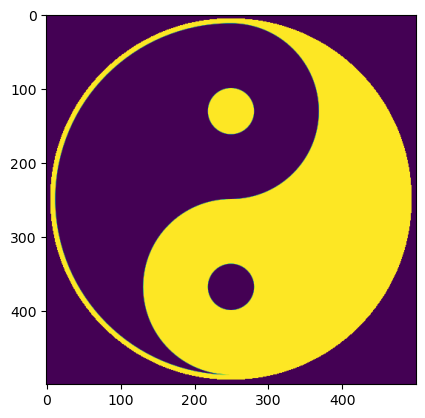

Target Size (m): 10.0
FOV Size (m): 35.0
Scale Factor: 0.2857142857142857
625


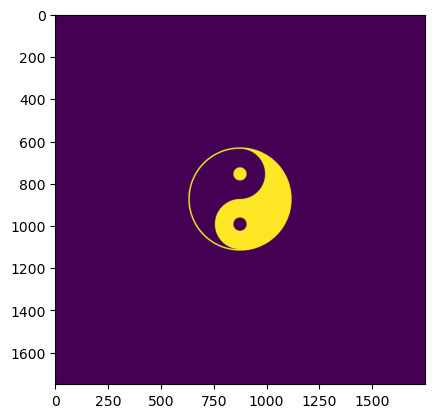

Image Dims:(1750, 1750)
Comp Grid Dims:(379, 379)
Pixel Scale Factor:4.617414248021108


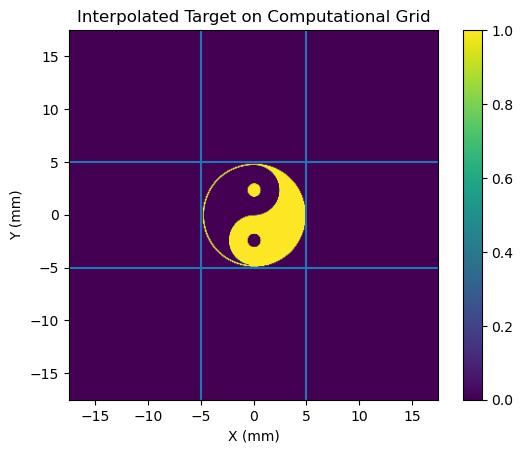

In [128]:
# --------------------------------------------------
# Load target image
# --------------------------------------------------

target = np.array(
    Image.open("Yin_yang_filled.png").convert("L"),
    dtype=float
)

target /= target.max()

target = 1- target

plt.imshow(target)
plt.show()

print('Target Size (m): ' + str(image_width*1e3))
print('FOV Size (m): ' + str(Lx*1e3))

Image_shrink_factor = image_width/Lx

print('Scale Factor: ' + str(Image_shrink_factor))

pad_size = int((1/Image_shrink_factor-1) * np.shape(target)[0]/2)
print(pad_size)

target_padded = np.pad(target, pad_size)
plt.imshow(target_padded)
plt.show()

print('Image Dims:' + str(np.shape(target_padded)))
print('Comp Grid Dims:' + str(np.shape(X)))

imag_px_per_comp_px = np.shape(target_padded)[0]/np.shape(X)[0]
print('Pixel Scale Factor:' + str(imag_px_per_comp_px))

from scipy.interpolate import RegularGridInterpolator

# Define the coordinates of the original padded image
# Assuming the image is centered and has a pixel pitch of dx (or similar)
# Since target_padded was derived from target, we need its spatial extent
img_shape = target_padded.shape
img_dx = dx/imag_px_per_comp_px #

img_xv = np.linspace(-img_shape[1]*img_dx/2, img_shape[1]*img_dx/2, img_shape[1])
img_yv = np.linspace(-img_shape[0]*img_dx/2, img_shape[0]*img_dx/2, img_shape[0])

# Create the interpolator
interp_func = RegularGridInterpolator((img_yv, img_xv), target_padded, bounds_error=False, fill_value=0)

# Interpolate onto the computational grid X, Y
# Note: RegularGridInterpolator expects points in (y, x) order if the array is (rows, cols)
points = np.stack([Y.ravel(), X.ravel()], axis=-1)
target_interpolated = interp_func(points).reshape(X.shape)

plt.imshow(target_interpolated, extent=[xv[0]*1e3, xv[-1]*1e3, yv[0]*1e3, yv[-1]*1e3])

plt.hlines(-image_width*1e3/2,xmin=xv[0]*1e3,xmax=xv[-1]*1e3)
plt.hlines(image_width*1e3/2,xmin=xv[0]*1e3,xmax=xv[-1]*1e3)
plt.vlines(-image_width*1e3/2,ymin=yv[0]*1e3,ymax=yv[-1]*1e3)
plt.vlines(image_width*1e3/2,ymin=yv[0]*1e3,ymax=yv[-1]*1e3)

plt.xlabel('X (mm)')
plt.ylabel('Y (mm)')

plt.colorbar()
plt.title("Interpolated Target on Computational Grid")
plt.show()



Original grid shape: (379, 379)
Downsampled grid shape: (379, 379)
Original image shape: (379, 379)
Downsampled image shape: (379, 379)
{143641}


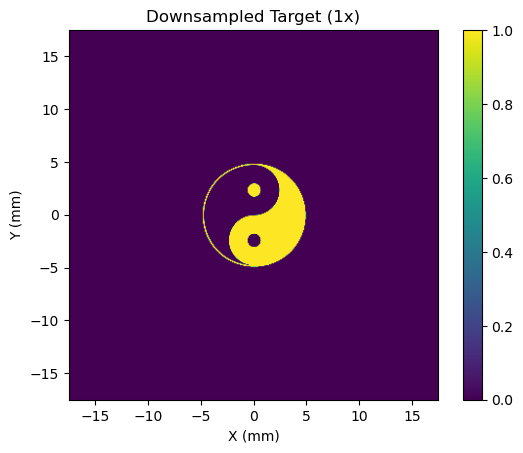

In [129]:
# Downsampling factor
ds_factor = 1

# Downsample the computational grid
# We slice the coordinate vectors first, then recreate the meshgrid
xv_ds = xv[::ds_factor]
yv_ds = yv[::ds_factor]
X_ds, Y_ds = np.meshgrid(xv_ds, yv_ds)

# Downsample the target image
# Slicing both dimensions by the factor
target_interpolated_ds = target_interpolated[::ds_factor, ::ds_factor]
# # Define threshold and binarise the downsampled interpolated image
# threshold = 0.01
# target_binarised_ds = (target_interpolated_ds > threshold).astype(np.uint8)

# Update dx for the downsampled grid
dx_ds = dx * ds_factor

print(f"Original grid shape: {X.shape}")
print(f"Downsampled grid shape: {X_ds.shape}")
print(f"Original image shape: {target_interpolated.shape}")
print(f"Downsampled image shape: {target_interpolated_ds.shape}")
print({target_interpolated_ds.shape[0]**2})

# Optional: Visualize to verify
plt.imshow(target_interpolated_ds, extent=[xv_ds[0]*1e3, xv_ds[-1]*1e3, yv_ds[0]*1e3, yv_ds[-1]*1e3])
plt.title(f"Downsampled Target ({ds_factor}x)")
plt.xlabel('X (mm)')
plt.ylabel('Y (mm)')
plt.colorbar()
plt.show()

In [130]:

# 3. Calculate positions of waypoints from the binarised image
# Find indices where the image is "active" (1)
y_indices, x_indices = np.where(target_interpolated_ds > 0)

# Convert pixel indices to waypoints (x, y)
waypoints = np.column_stack((x_indices, y_indices))

print(f"Extracted {len(waypoints)} waypoints from bitmap.")

Extracted 4799 waypoints from bitmap.


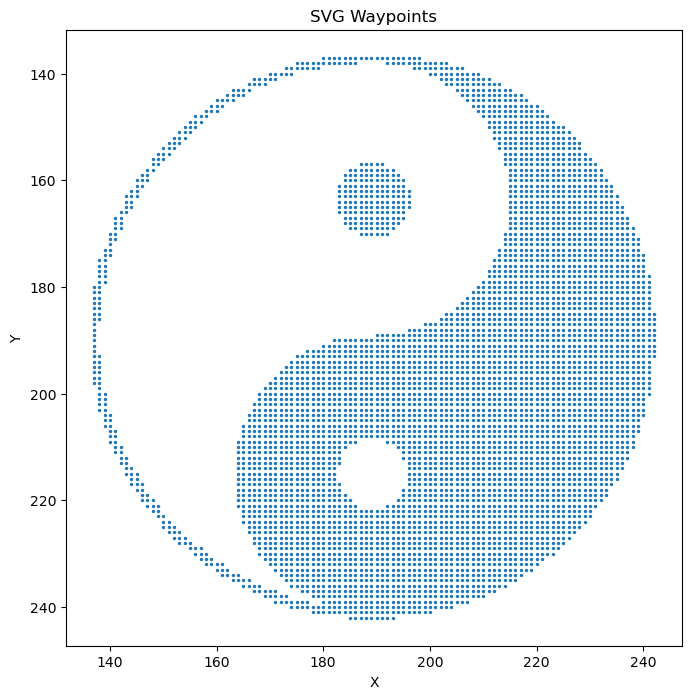

In [131]:
# Unzip the waypoints into x and y coordinates
x_coords, y_coords = zip(*waypoints)

plt.figure(figsize=(8, 8))
plt.scatter(x_coords, y_coords, marker='o', s=2)
plt.gca().set_aspect('equal', adjustable='box')
plt.title('SVG Waypoints')
plt.xlabel('X')
plt.ylabel('Y')
plt.gca().invert_yaxis()  # SVG coordinates usually have Y increasing downwards
# plt.grid(True)
plt.show()

In [132]:
xmin = np.min(x_coords)
xmax = np.max(x_coords)
ymin = np.min(y_coords)
ymax = np.max(y_coords)

x_length = xmax-xmin
y_length = ymax-ymin

x_centre = (xmax+xmin)/2
y_centre = (ymax+ymin)/2

centre = np.array([x_centre,y_centre])

waypoints_centered = np.array(waypoints-centre)

In [133]:
# image_width = 20e-3

image_scale_factor = x_length/image_width # be careful with non_square images
image_scale_factor = y_length/image_width 

print(image_scale_factor)

10500.0


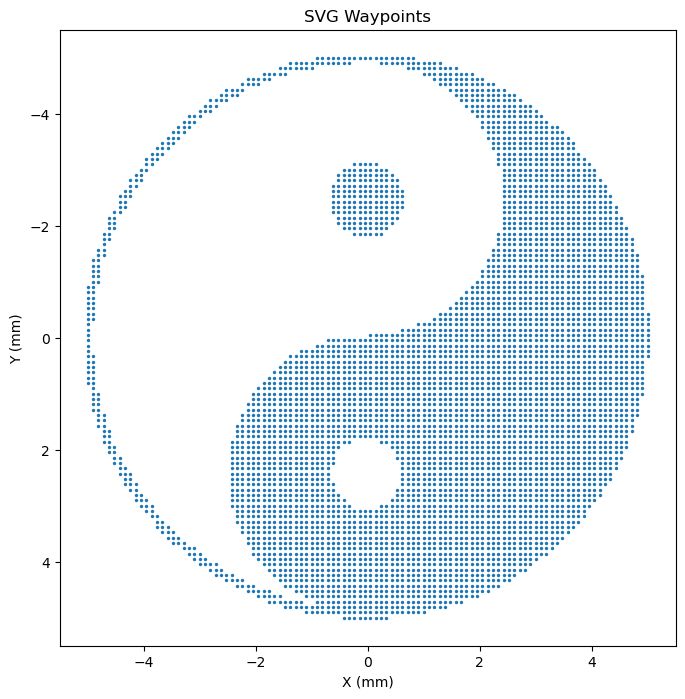

In [134]:
waypoints_mm  = (waypoints_centered/image_scale_factor)*1e3
x_coords_mm, y_coords_mm = zip(*waypoints_mm)


plt.figure(figsize=(8, 8))
plt.scatter(x_coords_mm, y_coords_mm, marker='o', s=2)
plt.gca().set_aspect('equal', adjustable='box')
plt.title('SVG Waypoints')
plt.xlabel('X (mm)')
plt.ylabel('Y (mm)')
plt.gca().invert_yaxis()  # SVG coordinates usually have Y increasing downwards
# plt.grid(True)
plt.show()

In [135]:
import numpy as np


def merge_point_pairs_by_distance(waypoints, dx_threshold):
    """
    Merge nearby waypoints, but only two points can be merged per pass.

    For each point, the function finds its nearest unmerged neighbour.
    If that neighbour is within dx_threshold, the two points are replaced
    by their centroid. Otherwise, the original point is kept.

    Parameters
    ----------
    waypoints : array-like, shape (N, D)
        Input waypoint coordinates.
        Works for 2D points such as (x, y), or 3D points such as (x, y, z).

    dx_threshold : float
        Maximum distance between two points for them to be merged.

    Returns
    -------
    merged_points : ndarray, shape (M, D)
        Updated list of points after one merge pass.
    """

    points = np.asarray(waypoints, dtype=float)
    n_points = len(points)

    if n_points == 0:
        return np.empty((0, points.shape[1] if points.ndim > 1 else 0))

    used = np.zeros(n_points, dtype=bool)
    merged_points = []

    for i in range(n_points):

        if used[i]:
            continue

        # Calculate Euclidean distance from point i to all other points
        distances = np.linalg.norm(points - points[i], axis=1)

        # Ignore itself and already-used points
        distances[i] = np.inf
        distances[used] = np.inf

        # Find nearest available neighbour
        nearest_index = np.argmin(distances)
        nearest_distance = distances[nearest_index]

        if nearest_distance <= dx_threshold:
            # Merge only this pair
            centroid = 0.5 * (points[i] + points[nearest_index])
            merged_points.append(centroid)

            used[i] = True
            used[nearest_index] = True

        else:
            # Keep original point
            merged_points.append(points[i])
            used[i] = True

    return np.array(merged_points)

dx_mm = 0.5
# dx_mm = dx_optimal*1e3/2
print(f'Merging waypoints with dx threshold: {dx_mm:.3f} mm')

n_iterations = 5
merged_waypoints = waypoints_mm

for _ in tqdm(range(n_iterations)):
    merged_waypoints = merge_point_pairs_by_distance(merged_waypoints, dx_mm)

print('N='+str(len(merged_waypoints)))


Merging waypoints with dx threshold: 0.500 mm


100%|██████████| 5/5 [00:00<00:00, 22.01it/s]

N=166


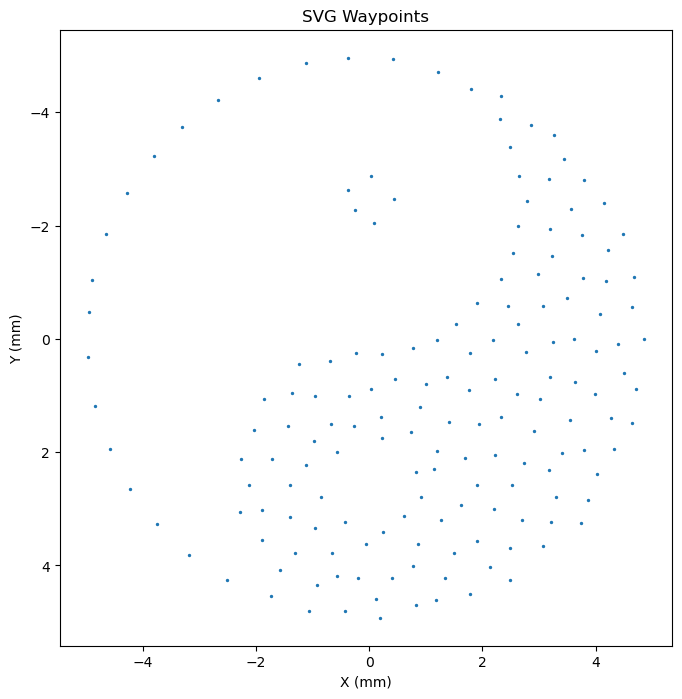

In [136]:
x,y = zip(*merged_waypoints)
coords = merged_waypoints*1e-3

# x,y = zip(*waypoints_mm*1e-3)
# coords = waypoints_mm*1e-3

plt.figure(figsize=(8, 8))
plt.scatter(coords[:,0]*1e3, coords[:,1]*1e3, marker='o', s=2)
plt.gca().set_aspect('equal', adjustable='box')
plt.title('SVG Waypoints')
plt.xlabel('X (mm)')
plt.ylabel('Y (mm)')
plt.gca().invert_yaxis()  # SVG coordinates usually have Y increasing downwards
# plt.grid(True)
plt.show()

In [137]:
# U = np.zeros_like(X)
# U_list = [genfocalPoint([coord[0], coord[1], focal_plane]) for coord in tqdm(coords)]
# U_ScAT = np.mean(U_list, axis=0)

U_ScAT = genfocalPoint([coords[0][0], coords[0][1], focal_plane]) *0

for coord in tqdm(coords):

    U_ScAT += genfocalPoint([coord[0], coord[1], focal_plane]) 
    
U_ScAT /= len(coords)

/var/folders/_f/7y9420f51bxgm9tns2f59x_r0000gp/T/ipykernel_30496/3593997293.py:94: RuntimeWarning: overflow encountered in exp
  H = np.exp(-1j*kz*z)
100%|██████████| 166/166 [00:28<00:00,  5.83it/s]


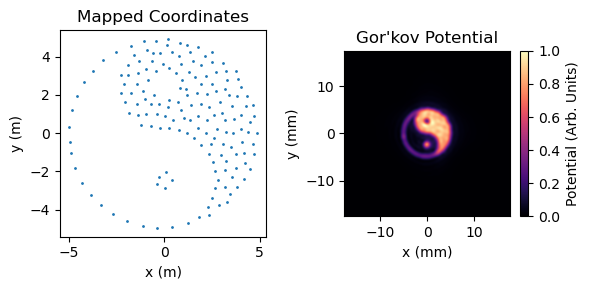

In [ ]:
plt.figure(figsize=(6,3))

fig = plt.gcf()
gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 0.05], wspace=0.35)

ax1 = fig.add_subplot(gs[0, 0])
ax1.scatter(coords[:, 0] * 1e3, coords[:, 1] * 1e3, s=1)
ax1.set_title("Mapped Coordinates")
ax1.set_xlabel("x (mm)")
ax1.set_ylabel("y (mm)")
ax1.set_aspect("equal")

ax2 = fig.add_subplot(gs[0, 1])
im = ax2.imshow(
    U_ScAT / np.max(U_ScAT),
    extent=[xv[0] * 1e3, xv[-1] * 1e3, yv[0] * 1e3, yv[-1] * 1e3],
    cmap="magma",
    origin="lower",
    vmin=0,
)
ax2.set_title("Gor'kov Potential")
ax2.set_xlabel("x (mm)")
ax2.set_ylabel("y (mm)")

cax = fig.add_subplot(gs[0, 2])
fig.colorbar(im, cax=cax, label="Potential (Arb. Units)")
# plt.axis('off')

plt.tight_layout()
plt.show()

In [139]:
period = len(coords)*20e-6
print(f'Estimated period for {len(coords)} waypoints: {period*1e3:.2f} ms')

Estimated period for 166 waypoints: 3.32 ms


In [140]:
coords_file_name = f"YinYang_{image_width*1e3:.0f}mm_{len(coords)}Points.csv"
np.savetxt(
    coords_file_name,
    coords,
    delimiter=",",
    header="x_m,y_m",
    comments="",
)
print(f"Mapped coordinates saved to {coords_file_name}")

Mapped coordinates saved to YinYang_10mm_166Points.csv
